#**Proyek Praktisi**

## Setup Data

In [65]:
import pandas as pd
import numpy as np

DATA_URL = (
    "https://raw.githubusercontent.com/"
    "nurhikam/mkb-ml-project/main/"
    "kasus/04-diagnosis-bearing/data/raw.csv"
)

df = pd.read_csv(DATA_URL)

print("Ukuran dataset:", df.shape)
print("\nNama kolom:")
print(df.columns.tolist())

print("\n5 data pertama:")
display(df.head())

print("\nDistribusi target:")
if "kondisi" in df.columns:
    print(df["kondisi"].value_counts())
else:
    print("Kolom kondisi belum ditemukan.")

Ukuran dataset: (15220, 14)

Nama kolom:
['id_rekaman', 'posisi_sensor', 'kecepatan_rpm', 'beban_kN', 'suhu_housing_C', 'rms_g', 'puncak_g', 'kurtosis', 'crest_factor', 'energi_bpfo', 'energi_bpfi', 'energi_bsf', 'frekuensi_dominan_hz', 'kondisi']

5 data pertama:


,id_rekaman,posisi_sensor,kecepatan_rpm,beban_kN,suhu_housing_C,rms_g,puncak_g,kurtosis,crest_factor,energi_bpfo,energi_bpfi,energi_bsf,frekuensi_dominan_hz,kondisi
0,REC-06504,drive_end,2547.0,2.79,53.8,0.5168,1.1658,0.039,2.256,0.1400,0.0436,0.0629,40.9,NORMAL
1,REC-02314,drive_end,1824.0,0.54,47.9,0.3603,1.1888,2.109,3.300,0.1309,0.0031,0.1030,116.0,outer
2,REC-01359,drive_end,2865.0,3.72,53.7,0.6982,2.0926,1.224,2.997,0.1902,0.0680,0.1525,46.5,normal
3,REC-12268,drive_end,2796.0,1.15,51.8,0.4973,1.4369,2.706,2.890,0.0788,0.0662,0.0441,46.4,normal
4,REC-06543,fan_end,2419.0,2.09,55.3,0.5089,1.6455,2.894,3.234,0.0230,0.0045,0.1951,82.7,bola



Distribusi target:
kondisi
normal        7863
outer_race    2894
inner_race    2072
bola          1476
ok             164
NORMAL         154
Normal         150
outer           72
Outer Race      67
IR              57
OR              55
BALL            43
inner           43
Inner Race      41
ball            39
Bola            30
Name: count, dtype: int64


In [66]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15220 entries, 0 to 15219
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id_rekaman            15220 non-null  object 
 1   posisi_sensor         15220 non-null  object 
 2   kecepatan_rpm         15220 non-null  float64
 3   beban_kN              15220 non-null  float64
 4   suhu_housing_C        15067 non-null  float64
 5   rms_g                 15220 non-null  float64
 6   puncak_g              15220 non-null  float64
 7   kurtosis              14764 non-null  float64
 8   crest_factor          15220 non-null  float64
 9   energi_bpfo           15220 non-null  float64
 10  energi_bpfi           15220 non-null  float64
 11  energi_bsf            15220 non-null  float64
 12  frekuensi_dominan_hz  15220 non-null  float64
 13  kondisi               15220 non-null  object 
dtypes: float64(11), object(3)
memory usage: 1.6+ MB


In [67]:
try:
    from google.colab import sheets
    sheet = sheets.InteractiveSheet(df=df)
except ImportError:
    print("Bukan di Colab, lewati sel ini.")

https://docs.google.com/spreadsheets/d/10lDFvGRtl8CXKcdazjk_hIb2iNdKZf-UrVp6jmFdUVc/edit#gid=0


## Data Cleaning

In [68]:
# ==========================================
# 2. MEMERIKSA MISSING VALUES
# ==========================================

print("=== MISSING VALUES SEBELUM CLEANING ===")

missing = df.isnull().sum()

missing_table = pd.DataFrame({
    "Jumlah Missing": missing,
    "Persentase (%)": (missing / len(df) * 100).round(2)
})

display(missing_table)

print("Total missing values:", df.isnull().sum().sum())

=== MISSING VALUES SEBELUM CLEANING ===


,Jumlah Missing,Persentase (%)
id_rekaman,0,0.00
posisi_sensor,0,0.00
kecepatan_rpm,0,0.00
beban_kN,0,0.00
suhu_housing_C,153,1.01
rms_g,0,0.00
puncak_g,0,0.00
kurtosis,456,3.00
crest_factor,0,0.00
energi_bpfo,0,0.00


Total missing values: 609


In [69]:
# ==========================================
# 3. MEMBERSIHKAN FORMAT DATA
# ==========================================

df.columns = df.columns.str.strip()

for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

if "posisi_sensor" in df.columns:
    df["posisi_sensor"] = df["posisi_sensor"].str.lower()

if "kondisi" not in df.columns:
    raise ValueError(
        "Kolom 'kondisi' tidak ditemukan. Periksa kembali dataset yang digunakan."
    )

df["kondisi"] = df["kondisi"].str.lower()

print("Format data berhasil diperiksa.")
print("\nKategori posisi_sensor:")
print(df["posisi_sensor"].value_counts(dropna=False))
print("\nKategori kondisi bearing:")
print(df["kondisi"].value_counts(dropna=False))

Format data berhasil diperiksa.

Kategori posisi_sensor:
posisi_sensor
drive_end    9021
fan_end      6199
Name: count, dtype: int64

Kategori kondisi bearing:
kondisi
normal        8167
outer_race    2894
inner_race    2072
bola          1506
ok             164
ball            82
outer           72
outer race      67
ir              57
or              55
inner           43
inner race      41
Name: count, dtype: int64


In [70]:
# ==========================================
# 4. MENGHAPUS DATA DUPLIKAT
# ==========================================

jumlah_awal = len(df)
jumlah_duplikat = df.duplicated().sum()
print("Jumlah baris duplikat identik:", jumlah_duplikat)

df = df.drop_duplicates().copy()

if "id_rekaman" in df.columns:
    duplikat_id = df.duplicated(subset=["id_rekaman"]).sum()
    print("Jumlah duplikat id_rekaman  :", duplikat_id)
    if duplikat_id > 0:
        df = df.drop_duplicates(subset=["id_rekaman"], keep="first").copy()

jumlah_akhir = len(df)
print("Data sebelum cleaning :", jumlah_awal)
print("Data setelah cleaning :", jumlah_akhir)
print("Total data dihapus    :", jumlah_awal - jumlah_akhir)

Jumlah baris duplikat identik: 220
Jumlah duplikat id_rekaman  : 0
Data sebelum cleaning : 15220
Data setelah cleaning : 15000
Total data dihapus    : 220


In [71]:
# ==========================================
# 5. MEMERIKSA TIPE DATA & VALIDASI NILAI FISIKA
# ==========================================

print("=== TIPE DATA SEBELUM PERBAIKAN ===")
print(df.dtypes)

kolom_numerik = [
    "kecepatan_rpm",
    "beban_kN",
    "suhu_housing_C",
    "rms_g",
    "puncak_g",
    "kurtosis",
    "crest_factor",
    "energi_bpfo",
    "energi_bpfi",
    "energi_bsf",
    "frekuensi_dominan_hz"
]

for col in kolom_numerik:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.replace([np.inf, -np.inf], np.nan)

kolom_non_negatif = [
    "kecepatan_rpm",
    "beban_kN",
    "rms_g",
    "puncak_g",
    "crest_factor",
    "energi_bpfo",
    "energi_bpfi",
    "energi_bsf",
    "frekuensi_dominan_hz"
]

print("\n=== PEMERIKSAAN ANOMALI NILAI NEGATIF ===")
for col in kolom_non_negatif:
    if col in df.columns:
        jumlah_negatif = (df[col] < 0).sum()
        if jumlah_negatif > 0:
            print(f"- {col}: ditemukan {jumlah_negatif} nilai < 0 -> diubah menjadi NaN")
            df.loc[df[col] < 0, col] = np.nan

print("\n=== TIPE DATA SETELAH PERBAIKAN ===")
print(df.dtypes)

=== TIPE DATA SEBELUM PERBAIKAN ===
id_rekaman               object
posisi_sensor            object
kecepatan_rpm           float64
beban_kN                float64
suhu_housing_C          float64
rms_g                   float64
puncak_g                float64
kurtosis                float64
crest_factor            float64
energi_bpfo             float64
energi_bpfi             float64
energi_bsf              float64
frekuensi_dominan_hz    float64
kondisi                  object
dtype: object

=== PEMERIKSAAN ANOMALI NILAI NEGATIF ===
- rms_g: ditemukan 45 nilai < 0 -> diubah menjadi NaN

=== TIPE DATA SETELAH PERBAIKAN ===
id_rekaman               object
posisi_sensor            object
kecepatan_rpm           float64
beban_kN                float64
suhu_housing_C          float64
rms_g                   float64
puncak_g                float64
kurtosis                float64
crest_factor            float64
energi_bpfo             float64
energi_bpfi             float64
energi_bsf      

In [72]:
# ==========================================
# 6. NORMALISASI LABEL KONDISI BEARING & TARGET
# ==========================================

label_mapping = {
    "normal": "normal",
    "ok": "normal",
    "outer_race": "outer_race",
    "outer race": "outer_race",
    "outer": "outer_race",
    "or": "outer_race",
    "inner_race": "inner_race",
    "inner race": "inner_race",
    "inner": "inner_race",
    "ir": "inner_race",
    "bola": "bola",
    "ball": "bola"
}

df["kondisi"] = (
    df["kondisi"]
    .astype(str)
    .str.strip()
    .str.lower()
    .map(label_mapping)
)

missing_target = df["kondisi"].isnull().sum()
print("Missing / unmapped label pada target:", missing_target)

df = df.dropna(subset=["kondisi"]).copy()
assert df["kondisi"].notna().all(), "Terdapat label yang belum dipetakan!"

print("Jumlah data setelah membersihkan target:", len(df))
print("\nDistribusi kelas setelah normalisasi:")
print(df["kondisi"].value_counts())
print("\nJumlah kelas:", df["kondisi"].nunique())


Missing / unmapped label pada target: 0
Jumlah data setelah membersihkan target: 15000

Distribusi kelas setelah normalisasi:
kondisi
normal        8219
outer_race    3039
inner_race    2178
bola          1564
Name: count, dtype: int64

Jumlah kelas: 4


In [73]:
# ==========================================
# 7. PEMERIKSAAN AKHIR
# ==========================================

print("=== HASIL AKHIR DATA CLEANING ===")

print("Jumlah baris:", df.shape[0])
print("Jumlah kolom:", df.shape[1])

print("\nMissing values:")
display(df.isnull().sum().to_frame("Jumlah Missing"))

print("\nJumlah duplikasi:", df.duplicated().sum())

print("\nDistribusi kelas:")
display(df["kondisi"].value_counts().to_frame("Jumlah Data"))

print("\nInformasi dataset:")
df.info()

display(df.head())

=== HASIL AKHIR DATA CLEANING ===
Jumlah baris: 15000
Jumlah kolom: 14

Missing values:


,Jumlah Missing
id_rekaman,0
posisi_sensor,0
kecepatan_rpm,0
beban_kN,0
suhu_housing_C,150
rms_g,45
puncak_g,0
kurtosis,450
crest_factor,0
energi_bpfo,0



Jumlah duplikasi: 0

Distribusi kelas:


,Jumlah Data
kondisi,
normal,8219
outer_race,3039
inner_race,2178
bola,1564



Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
Index: 15000 entries, 0 to 15219
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id_rekaman            15000 non-null  object 
 1   posisi_sensor         15000 non-null  object 
 2   kecepatan_rpm         15000 non-null  float64
 3   beban_kN              15000 non-null  float64
 4   suhu_housing_C        14850 non-null  float64
 5   rms_g                 14955 non-null  float64
 6   puncak_g              15000 non-null  float64
 7   kurtosis              14550 non-null  float64
 8   crest_factor          15000 non-null  float64
 9   energi_bpfo           15000 non-null  float64
 10  energi_bpfi           15000 non-null  float64
 11  energi_bsf            15000 non-null  float64
 12  frekuensi_dominan_hz  15000 non-null  float64
 13  kondisi               15000 non-null  object 
dtypes: float64(11), object(3)
memory usage: 1.7+ MB


,id_rekaman,posisi_sensor,kecepatan_rpm,beban_kN,suhu_housing_C,rms_g,puncak_g,kurtosis,crest_factor,energi_bpfo,energi_bpfi,energi_bsf,frekuensi_dominan_hz,kondisi
0,REC-06504,drive_end,2547.0,2.79,53.8,0.5168,1.1658,0.039,2.256,0.1400,0.0436,0.0629,40.9,normal
1,REC-02314,drive_end,1824.0,0.54,47.9,0.3603,1.1888,2.109,3.300,0.1309,0.0031,0.1030,116.0,outer_race
2,REC-01359,drive_end,2865.0,3.72,53.7,0.6982,2.0926,1.224,2.997,0.1902,0.0680,0.1525,46.5,normal
3,REC-12268,drive_end,2796.0,1.15,51.8,0.4973,1.4369,2.706,2.890,0.0788,0.0662,0.0441,46.4,normal
4,REC-06543,fan_end,2419.0,2.09,55.3,0.5089,1.6455,2.894,3.234,0.0230,0.0045,0.1951,82.7,bola


In [74]:
# ==========================================
# 9. MENYIMPAN DATASET
# ==========================================

df.to_csv("bearing_cleaned.csv", index=False)

print("Dataset berhasil disimpan sebagai bearing_cleaned.csv")

Dataset berhasil disimpan sebagai bearing_cleaned.csv


## Train/Test Split

In [75]:
from sklearn.model_selection import train_test_split
import pandas as pd

In [76]:
# ==========================================
# 1. MENENTUKAN FITUR DAN TARGET
# ==========================================

X = df.drop(columns=["kondisi", "id_rekaman"], errors="ignore")
y = df["kondisi"]

print("Jumlah fitur:", X.shape[1])
print("Jumlah target:", y.shape[0])

print("\nDaftar fitur:")
print(X.columns.tolist())

print("\nDistribusi target:")
print(y.value_counts())

Jumlah fitur: 12
Jumlah target: 15000

Daftar fitur:
['posisi_sensor', 'kecepatan_rpm', 'beban_kN', 'suhu_housing_C', 'rms_g', 'puncak_g', 'kurtosis', 'crest_factor', 'energi_bpfo', 'energi_bpfi', 'energi_bsf', 'frekuensi_dominan_hz']

Distribusi target:
kondisi
normal        8219
outer_race    3039
inner_race    2178
bola          1564
Name: count, dtype: int64


In [77]:
# ==========================================
# 2. TRAINING SET (60%)
# ==========================================

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.40,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Temporary set:", X_temp.shape)

Training set: (9000, 12)
Temporary set: (6000, 12)


In [78]:
# ==========================================
# 3. VALIDATION DAN TESTING SET
# ==========================================

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training set  :", X_train.shape)
print("Validation set:", X_val.shape)
print("Testing set   :", X_test.shape)

Training set  : (9000, 12)
Validation set: (3000, 12)
Testing set   : (3000, 12)


In [79]:
# ==========================================
# 4. MEMERIKSA DISTRIBUSI KELAS
# ==========================================

distribusi = pd.DataFrame({
    "Full Dataset": y.value_counts(normalize=True) * 100,
    "Training": y_train.value_counts(normalize=True) * 100,
    "Validation": y_val.value_counts(normalize=True) * 100,
    "Testing": y_test.value_counts(normalize=True) * 100
})

distribusi = distribusi.fillna(0).round(2)

display(distribusi)

,Full Dataset,Training,Validation,Testing
kondisi,,,,
normal,54.79,54.80,54.77,54.80
outer_race,20.26,20.26,20.27,20.27
inner_race,14.52,14.52,14.53,14.50
bola,10.43,10.42,10.43,10.43


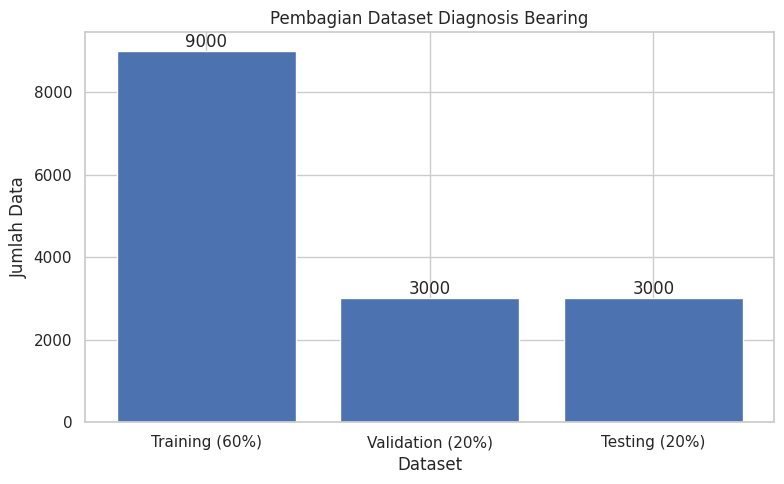

In [80]:
import matplotlib.pyplot as plt

jumlah_data = [
    len(X_train),
    len(X_val),
    len(X_test)
]

label = ["Training (60%)", "Validation (20%)", "Testing (20%)"]

plt.figure(figsize=(8, 5))

plt.bar(label, jumlah_data)

plt.title("Pembagian Dataset Diagnosis Bearing")
plt.ylabel("Jumlah Data")
plt.xlabel("Dataset")

for i, jumlah in enumerate(jumlah_data):
    plt.text(i, jumlah, str(jumlah), ha="center", va="bottom")

plt.tight_layout()
plt.show()

In [81]:
# ==========================================
# 5. RINGKASAN TRAIN-TEST SPLIT
# ==========================================

print("=== RINGKASAN DATASET ===")
print(f"Total data      : {len(X)}")
print(f"Training data   : {len(X_train)} ({len(X_train)/len(X)*100:.2f}%)")
print(f"Validation data : {len(X_val)} ({len(X_val)/len(X)*100:.2f}%)")
print(f"Testing data    : {len(X_test)} ({len(X_test)/len(X)*100:.2f}%)")

print("\n=== RINCIAN MISSING VALUES (AKAN DIIMPUTASI DI PREPROCESSING) ===")
missing_split = pd.DataFrame({
    "Training": X_train.isnull().sum(),
    "Validation": X_val.isnull().sum(),
    "Testing": X_test.isnull().sum()
})
display(missing_split[missing_split.sum(axis=1) > 0])

=== RINGKASAN DATASET ===
Total data      : 15000
Training data   : 9000 (60.00%)
Validation data : 3000 (20.00%)
Testing data    : 3000 (20.00%)

=== RINCIAN MISSING VALUES (AKAN DIIMPUTASI DI PREPROCESSING) ===


,Training,Validation,Testing
suhu_housing_C,96,28,26
rms_g,29,8,8
kurtosis,261,112,77


## Exploratory Data Analysis

In [82]:
# ==========================================
# 1. IMPORT LIBRARY
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

print("Library EDA berhasil diimport.")

Library EDA berhasil diimport.


In [83]:
# ==========================================
# 2. INFORMASI DATASET
# ==========================================

print("=== INFORMASI DATASET TRAINING ===")

print("Jumlah data training:", X_train.shape[0])
print("Jumlah fitur:", X_train.shape[1])

print("\nTipe data setiap fitur:")
display(X_train.dtypes.to_frame("Tipe Data"))

print("\nInformasi statistik:")
display(X_train.describe().T)

=== INFORMASI DATASET TRAINING ===
Jumlah data training: 9000
Jumlah fitur: 12

Tipe data setiap fitur:


,Tipe Data
posisi_sensor,object
kecepatan_rpm,float64
beban_kN,float64
suhu_housing_C,float64
rms_g,float64
puncak_g,float64
kurtosis,float64
crest_factor,float64
energi_bpfo,float64
energi_bpfi,float64



Informasi statistik:


,count,mean,std,min,25%,50%,75%,max
kecepatan_rpm,9000.0,2090.759667,532.801694,0.0000,1636.750000,2093.50000,2543.000000,3000.0000
beban_kN,9000.0,3.239294,1.576936,0.5000,1.870000,3.22000,4.600000,6.0000
suhu_housing_C,8904.0,52.723080,4.231478,39.9000,49.800000,52.60000,55.600000,67.9000
rms_g,8971.0,0.482347,0.137532,0.1822,0.378050,0.46880,0.572400,1.0992
puncak_g,9000.0,1.608855,0.532472,0.4632,1.216475,1.53500,1.927825,4.3333
kurtosis,8739.0,3.362854,0.961822,0.0390,2.701000,3.32400,3.976500,7.2270
crest_factor,9000.0,3.323297,0.446246,1.7790,3.025750,3.31200,3.615000,5.1170
energi_bpfo,9000.0,0.100170,0.082949,0.0000,0.040500,0.08015,0.135300,0.6983
energi_bpfi,9000.0,0.081095,0.066870,0.0000,0.031400,0.06550,0.111800,0.4994
energi_bsf,9000.0,0.072985,0.056507,0.0000,0.029800,0.06120,0.102400,0.4314


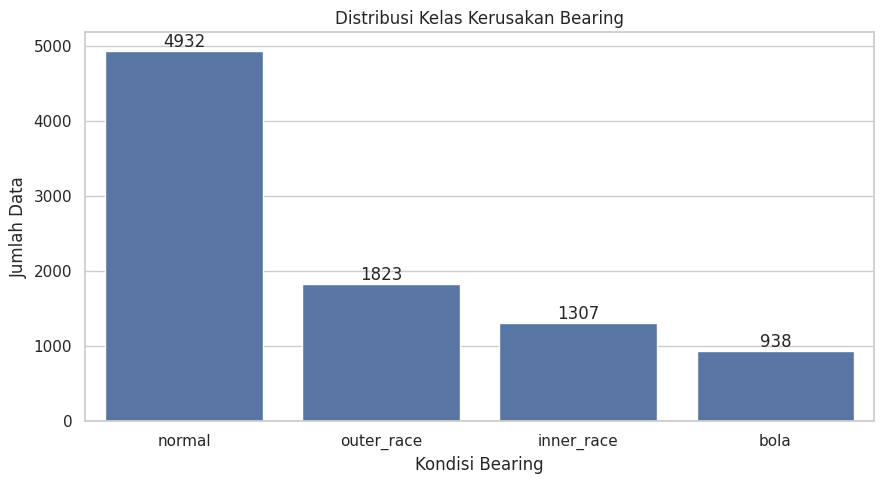


Persentase setiap kelas:


,Persentase (%)
kondisi,
normal,54.80
outer_race,20.26
inner_race,14.52
bola,10.42


In [84]:
# ==========================================
# 3. DISTRIBUSI KELAS BEARING
# ==========================================

plt.figure(figsize=(9, 5))

ax = sns.countplot(
    x=y_train,
    order=["normal", "outer_race", "inner_race", "bola"]
)

plt.title("Distribusi Kelas Kerusakan Bearing")
plt.xlabel("Kondisi Bearing")
plt.ylabel("Jumlah Data")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

print("\nPersentase setiap kelas:")
display(
    (y_train.value_counts(normalize=True) * 100)
    .round(2)
    .to_frame("Persentase (%)")
)

Fitur numerik yang dianalisis:
['kecepatan_rpm', 'beban_kN', 'suhu_housing_C', 'rms_g', 'puncak_g', 'kurtosis', 'crest_factor', 'energi_bpfo', 'energi_bpfi', 'energi_bsf', 'frekuensi_dominan_hz']


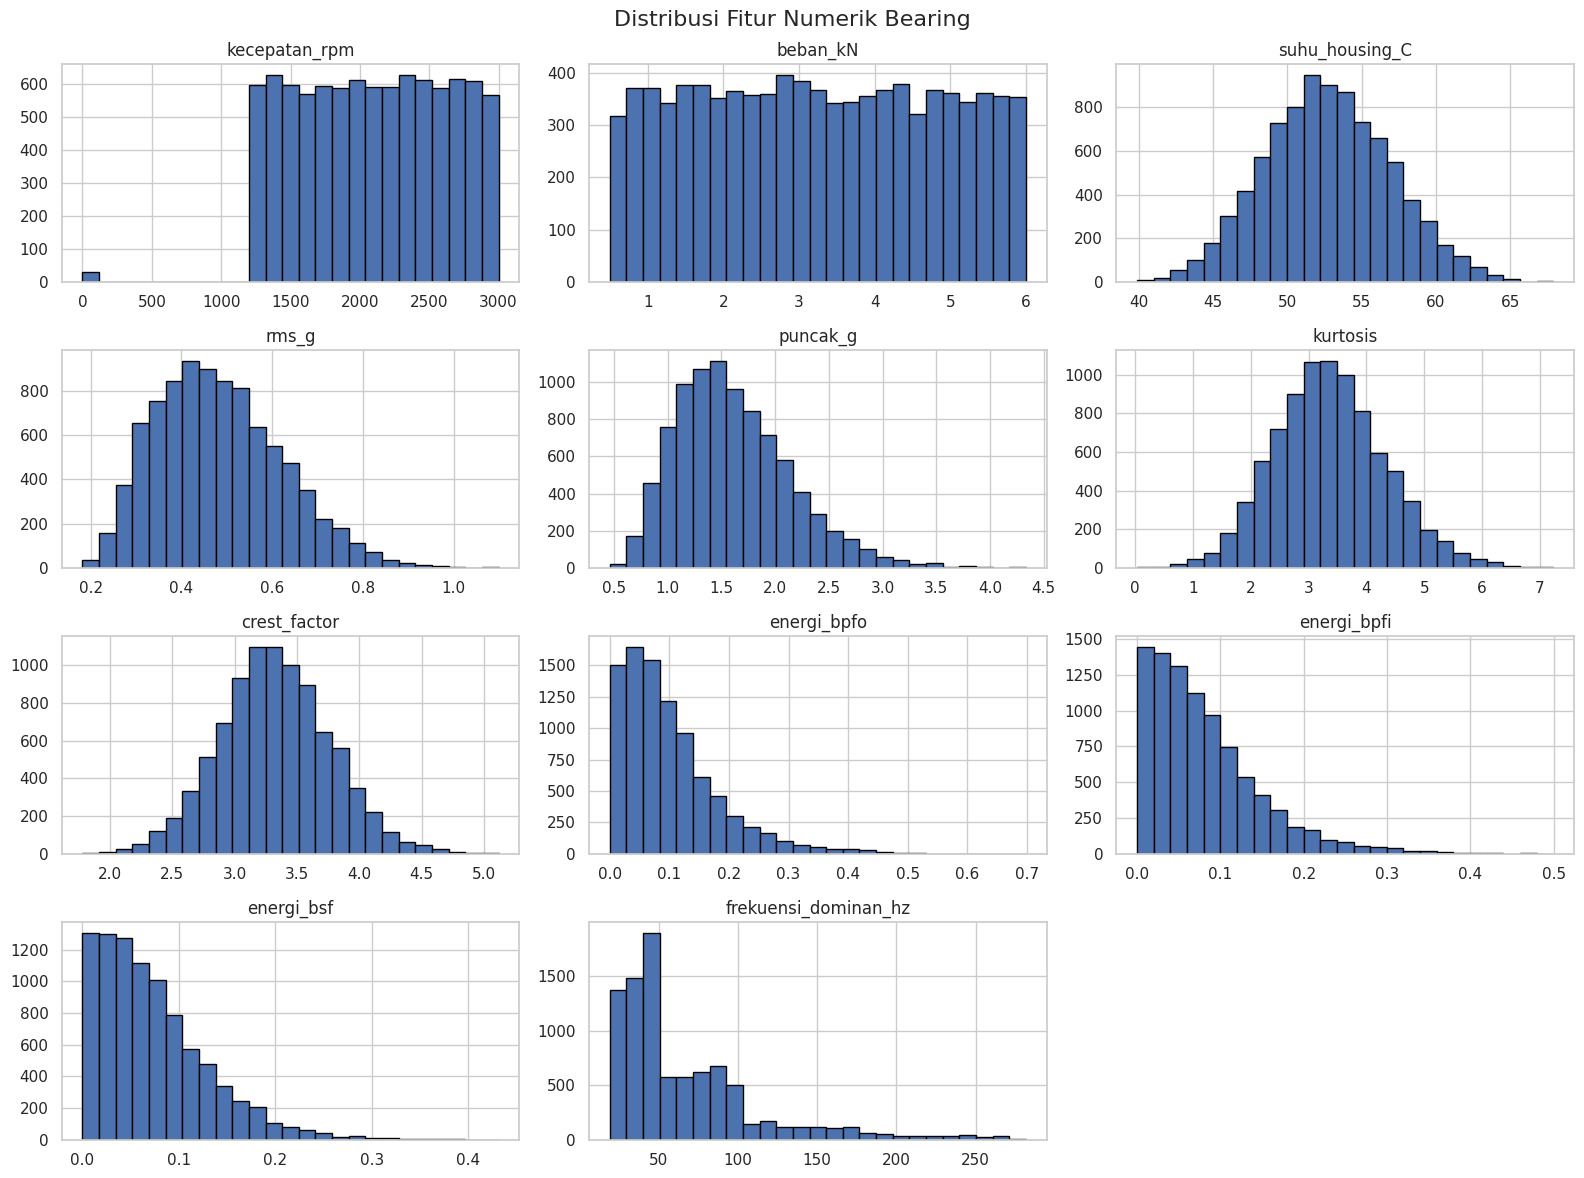

In [85]:
# ==========================================
# 4. DISTRIBUSI FITUR NUMERIK
# ==========================================

numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

numeric_features = [
    col for col in numeric_features
    if col != "id_rekaman"
]

print("Fitur numerik yang dianalisis:")
print(numeric_features)

X_train[numeric_features].hist(
    figsize=(16, 12),
    bins=25,
    edgecolor="black"
)

plt.suptitle(
    "Distribusi Fitur Numerik Bearing",
    fontsize=16
)

plt.tight_layout()
plt.show()

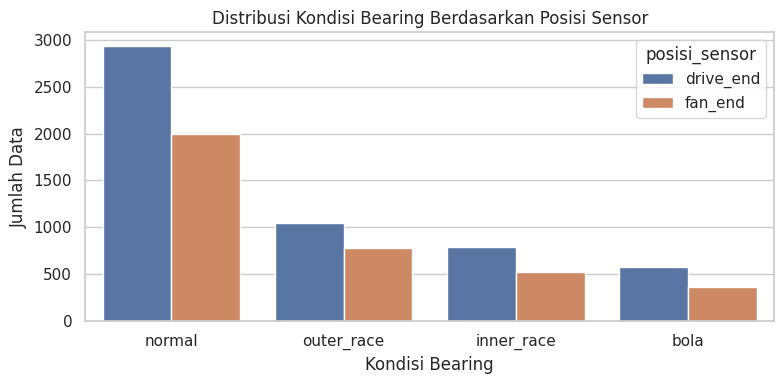

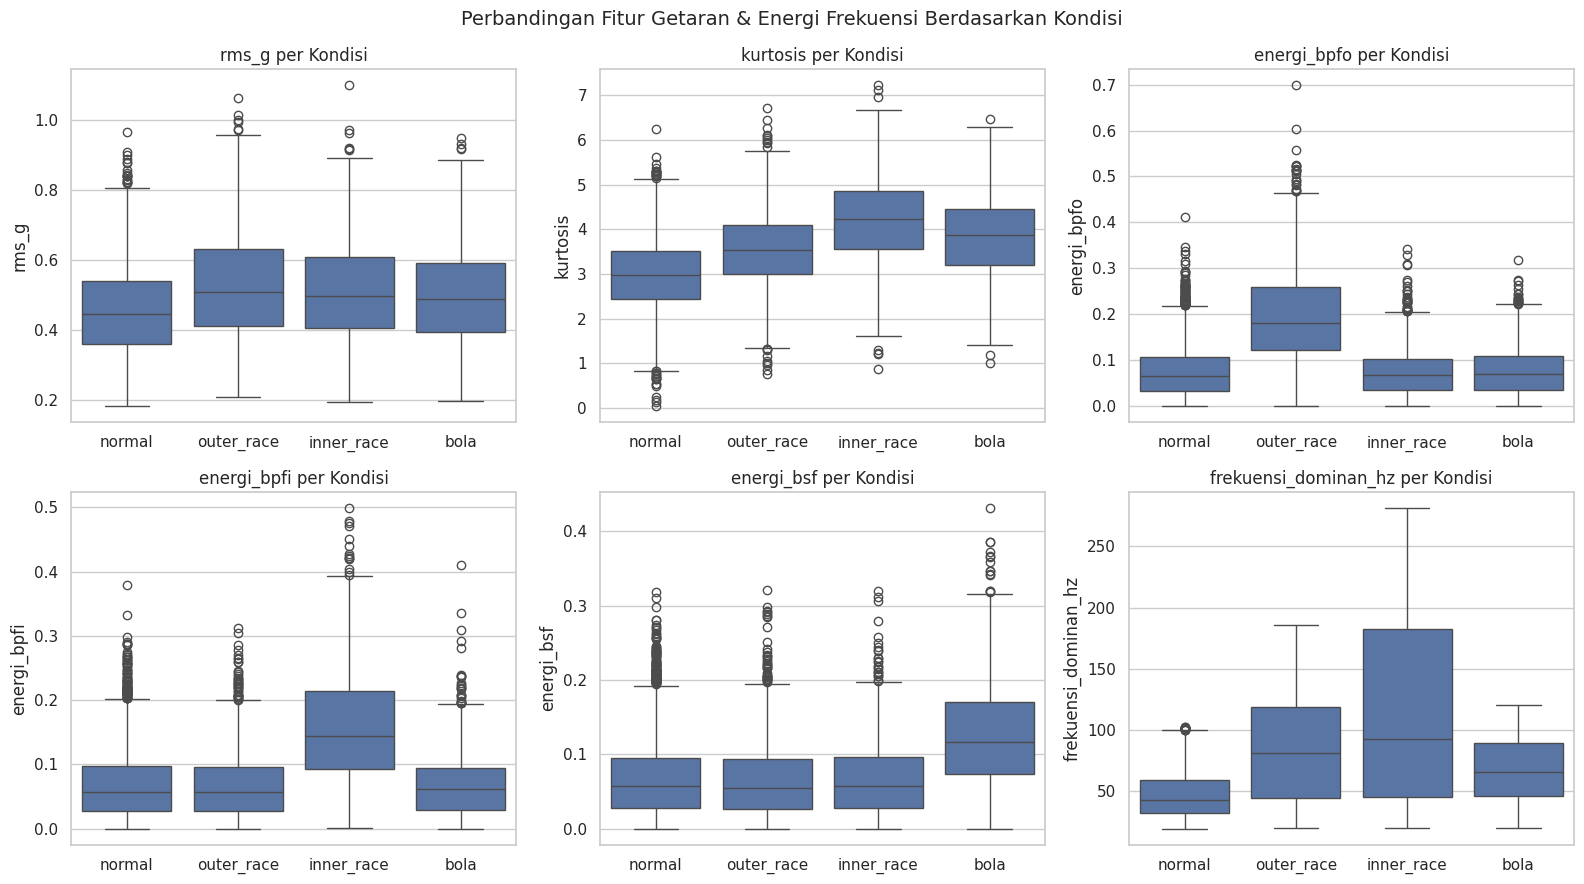

In [86]:
# ==========================================
# 5. ANALISIS FITUR UTAMA PER KONDISI BEARING
# ==========================================

train_eda = X_train.copy()
train_eda["kondisi"] = y_train
urutan_kelas = ["normal", "outer_race", "inner_race", "bola"]

plt.figure(figsize=(8, 4))
sns.countplot(data=train_eda, x="kondisi", hue="posisi_sensor", order=urutan_kelas)
plt.title("Distribusi Kondisi Bearing Berdasarkan Posisi Sensor")
plt.xlabel("Kondisi Bearing")
plt.ylabel("Jumlah Data")
plt.tight_layout()
plt.show()

fitur_kunci = ["rms_g", "kurtosis", "energi_bpfo", "energi_bpfi", "energi_bsf", "frekuensi_dominan_hz"]
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, col in enumerate(fitur_kunci):
    sns.boxplot(data=train_eda, x="kondisi", y=col, order=urutan_kelas, ax=axes[i])
    axes[i].set_title(f"{col} per Kondisi")
    axes[i].set_xlabel("")

plt.suptitle("Perbandingan Fitur Getaran & Energi Frekuensi Berdasarkan Kondisi", fontsize=14)
plt.tight_layout()
plt.show()

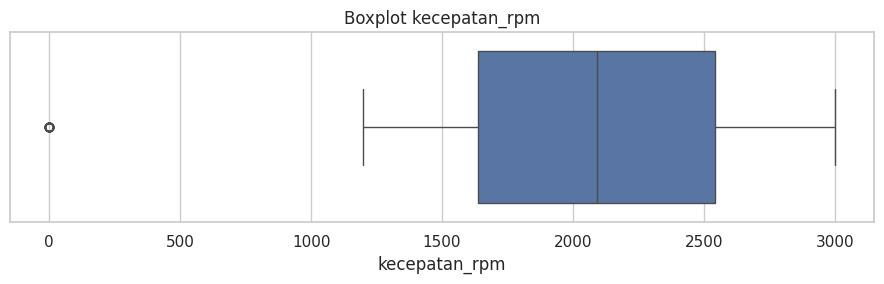

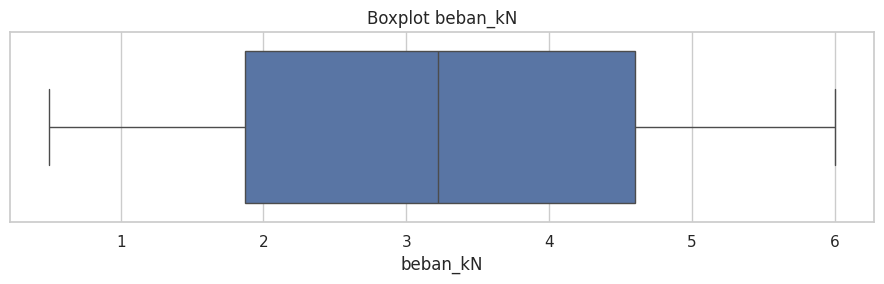

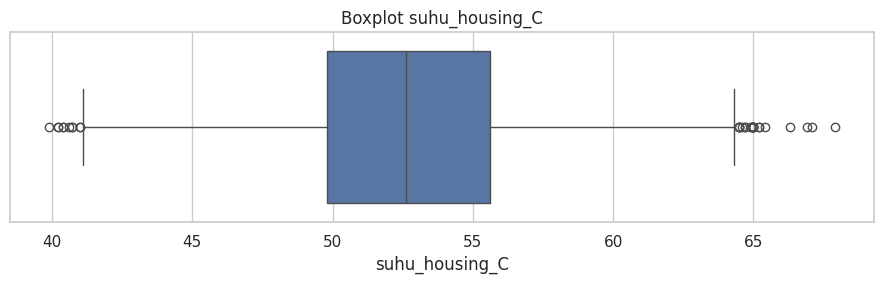

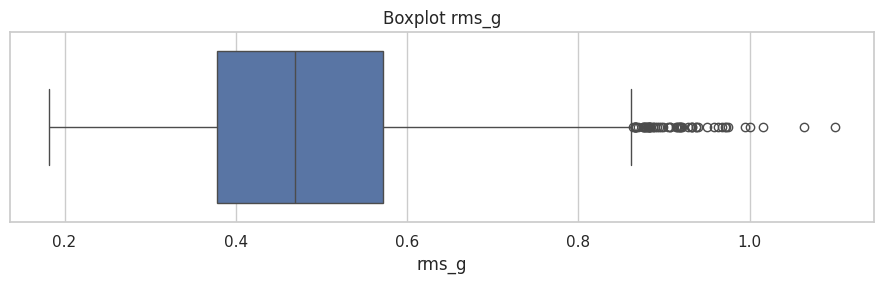

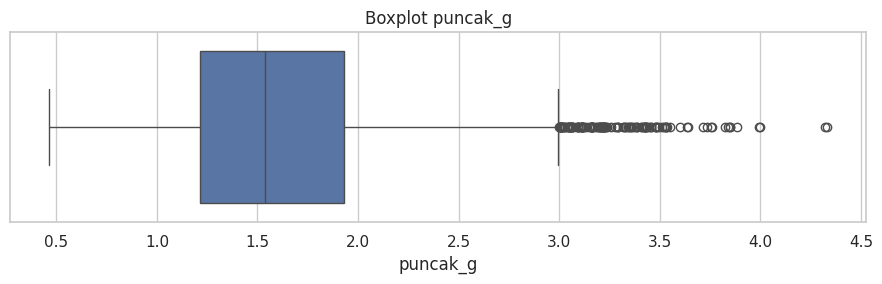

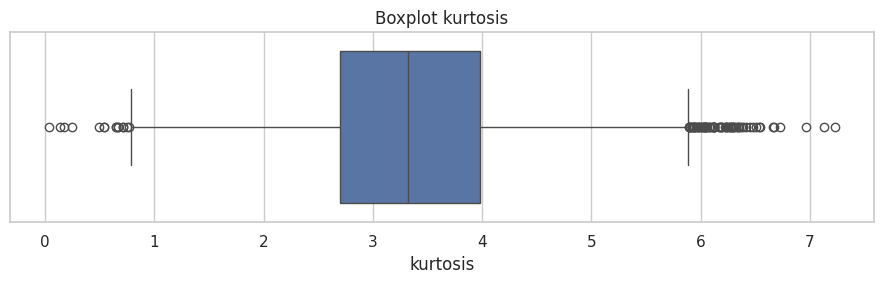

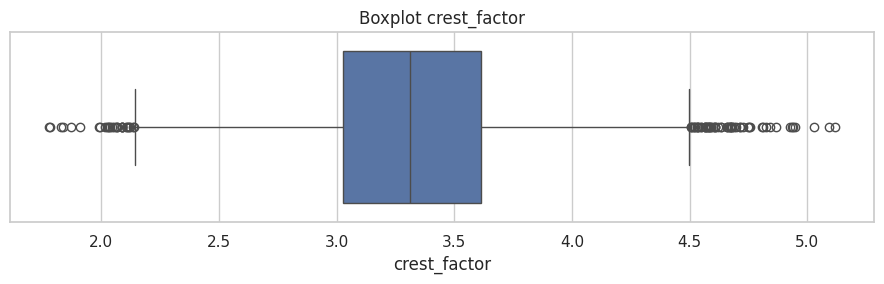

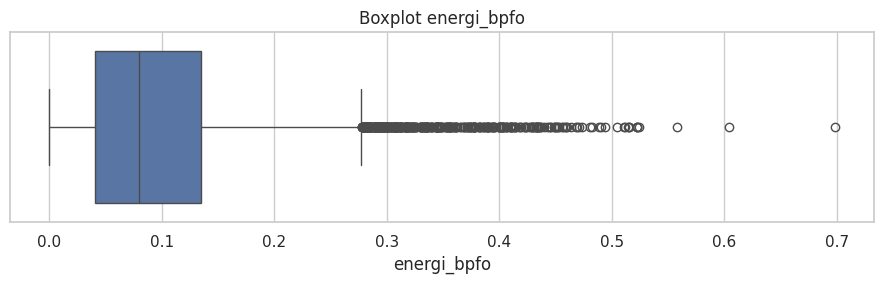

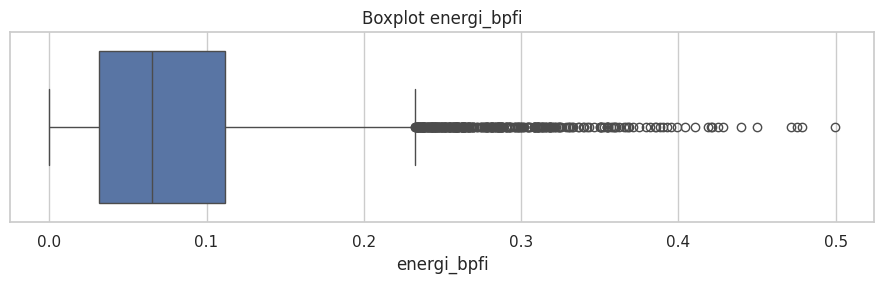

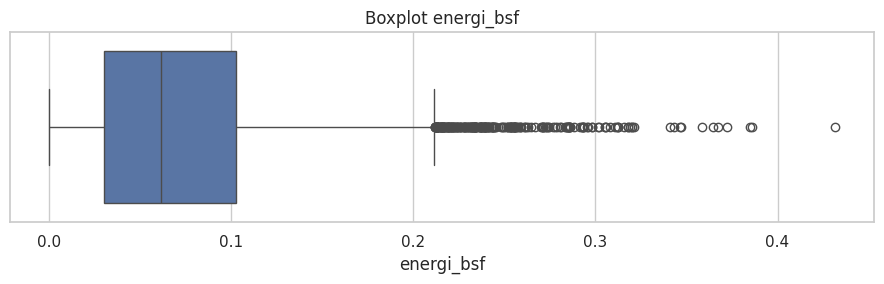

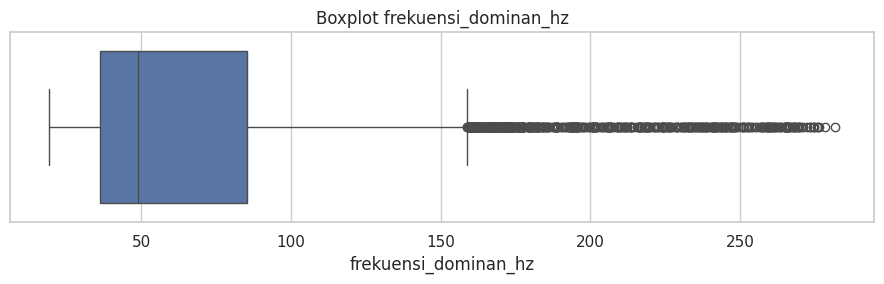

In [87]:
# ==========================================
# 6. DETEKSI OUTLIER DENGAN BOXPLOT
# ==========================================

for col in numeric_features:

    plt.figure(figsize=(9, 3))

    sns.boxplot(
        x=X_train[col]
    )

    plt.title(f"Boxplot {col}")
    plt.xlabel(col)

    plt.tight_layout()
    plt.show()

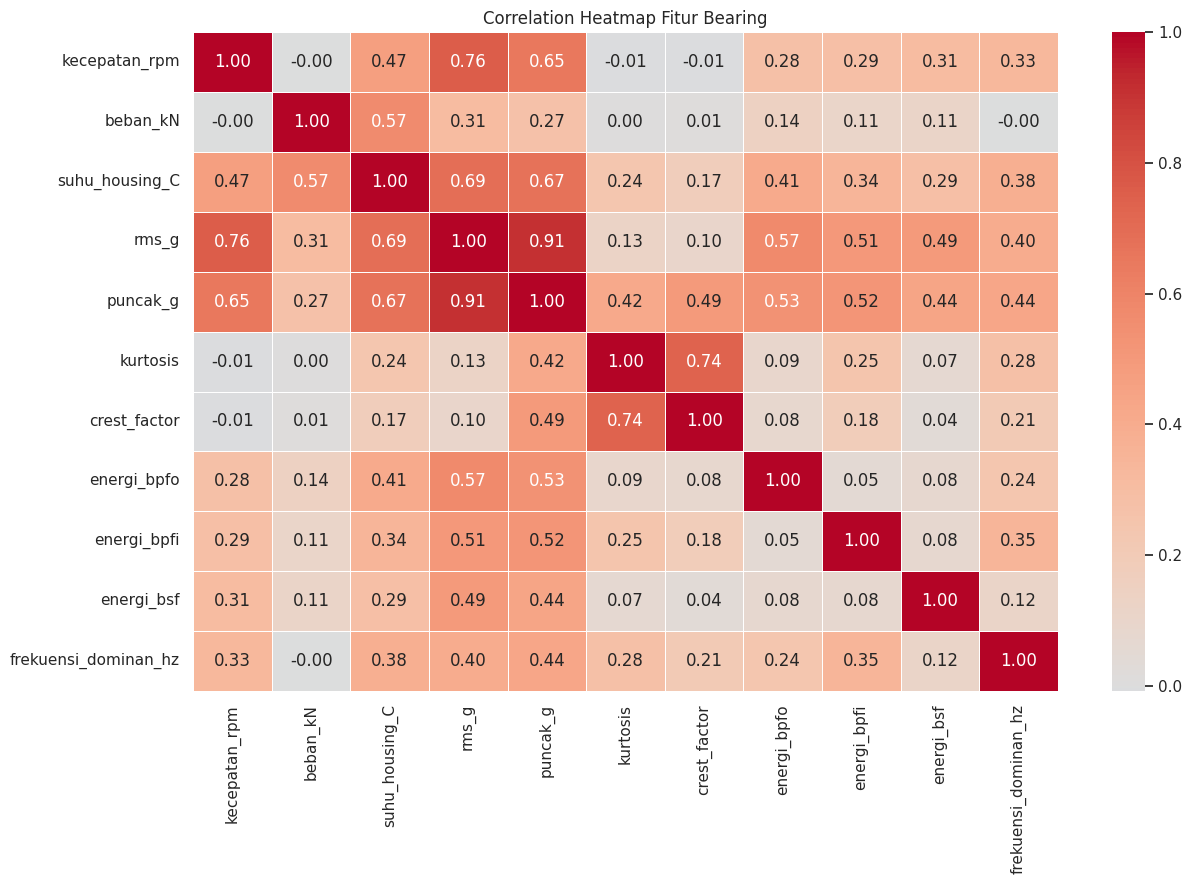

In [88]:
# ==========================================
# 7. CORRELATION HEATMAP
# ==========================================

correlation = X_train[numeric_features].corr()

plt.figure(figsize=(13, 9))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Correlation Heatmap Fitur Bearing")

plt.tight_layout()
plt.show()

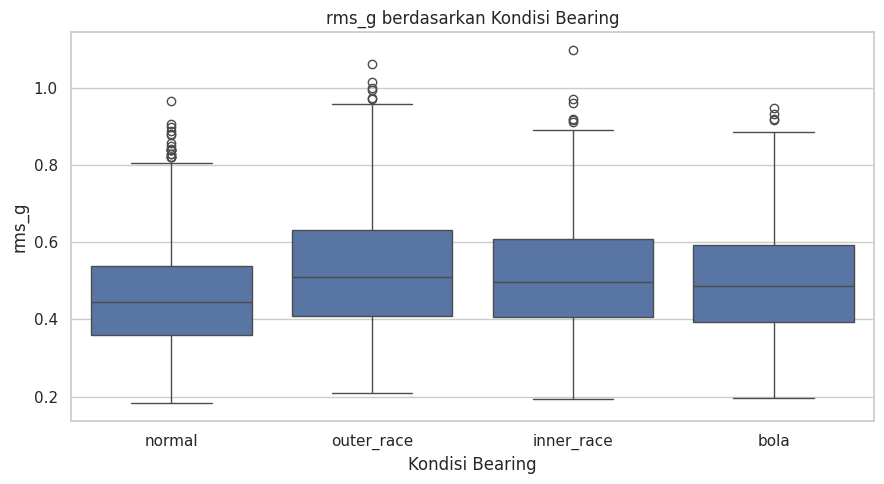

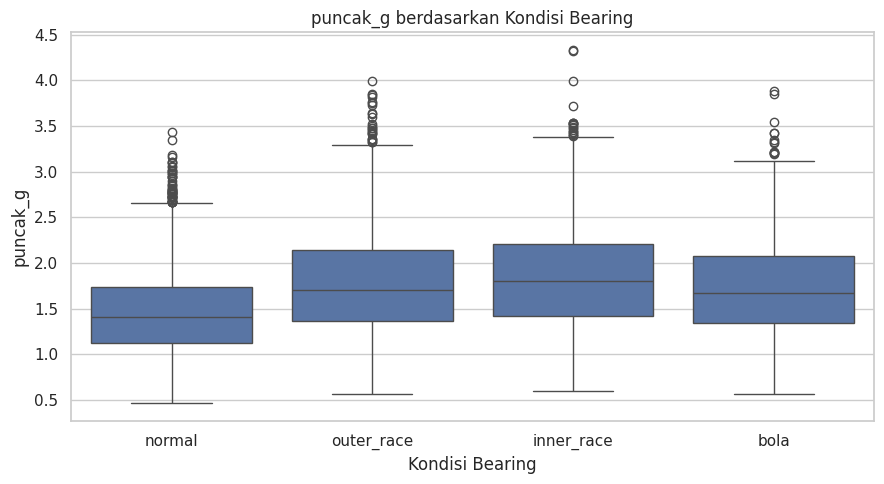

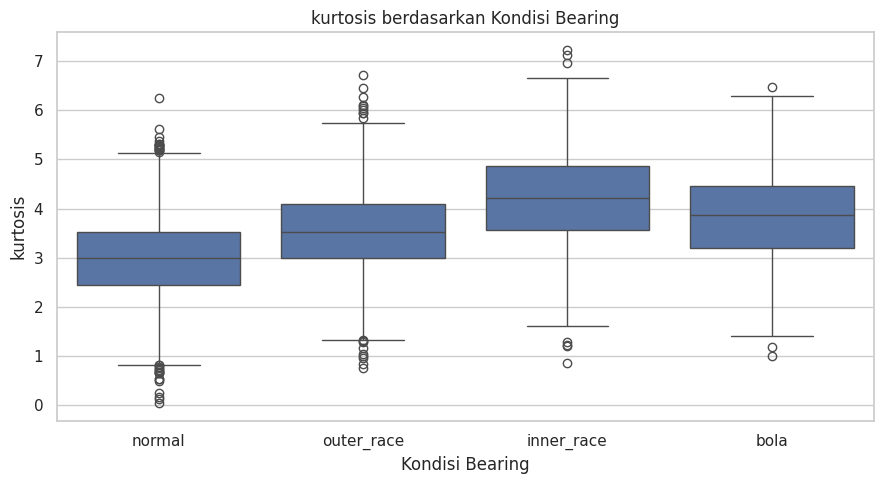

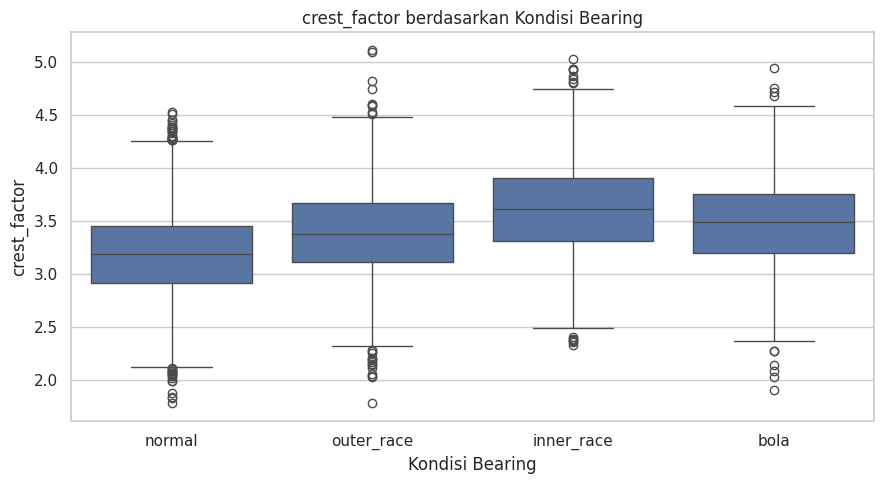

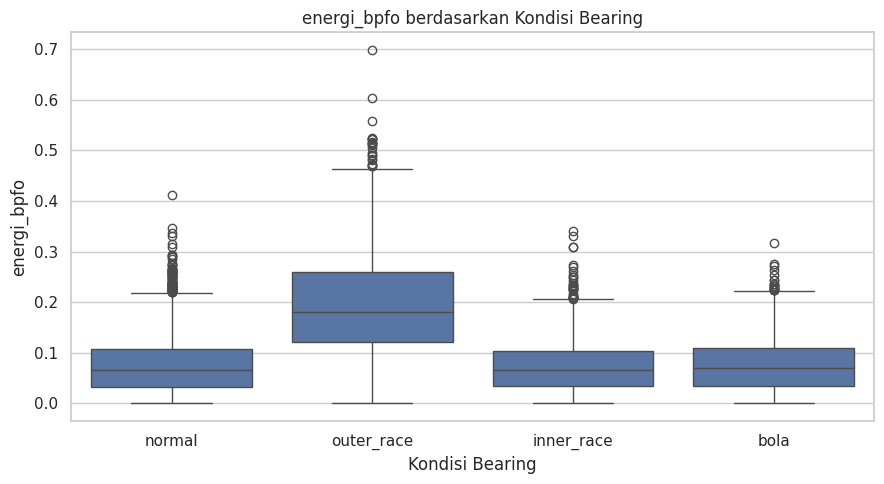

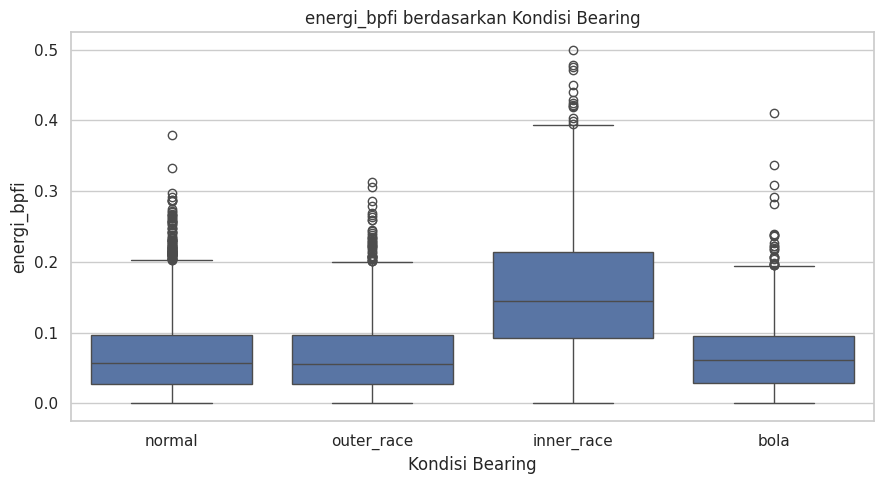

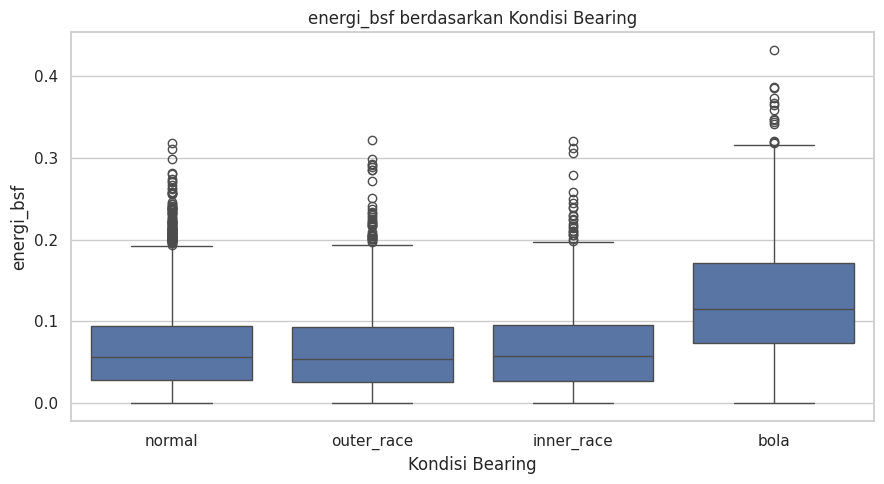

In [89]:
# ==========================================
# 8. HUBUNGAN FITUR DENGAN KONDISI BEARING
# ==========================================

data_eda = X_train.copy()

data_eda["kondisi"] = y_train

fitur_penting = [
    "rms_g",
    "puncak_g",
    "kurtosis",
    "crest_factor",
    "energi_bpfo",
    "energi_bpfi",
    "energi_bsf"
]

fitur_penting = [
    col for col in fitur_penting
    if col in data_eda.columns
]

for col in fitur_penting:

    plt.figure(figsize=(9, 5))

    sns.boxplot(
        data=data_eda,
        x="kondisi",
        y=col,
        order=["normal", "outer_race", "inner_race", "bola"]
    )

    plt.title(f"{col} berdasarkan Kondisi Bearing")
    plt.xlabel("Kondisi Bearing")
    plt.ylabel(col)

    plt.tight_layout()
    plt.show()

Fitur kategorikal: ['posisi_sensor']


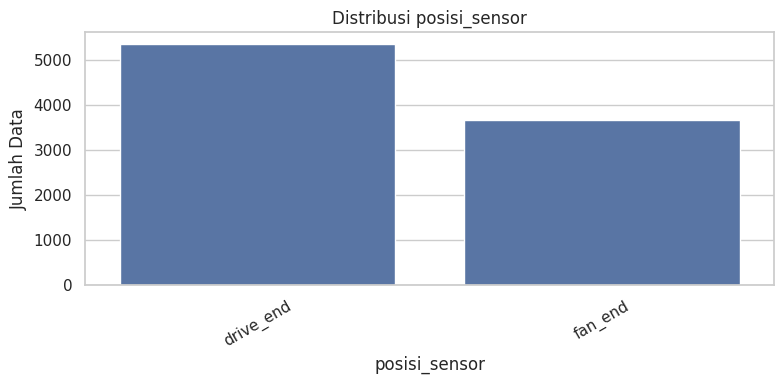

In [90]:
# ==========================================
# 9. DISTRIBUSI FITUR KATEGORIKAL
# ==========================================

categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Fitur kategorikal:", categorical_features)

for col in categorical_features:

    plt.figure(figsize=(8, 4))

    sns.countplot(
        data=X_train,
        x=col,
        order=X_train[col].value_counts().index
    )

    plt.title(f"Distribusi {col}")
    plt.xlabel(col)
    plt.ylabel("Jumlah Data")
    plt.xticks(rotation=30)

    plt.tight_layout()
    plt.show()

## Data Preprocessing

In [91]:
# ==========================================
# 1. IMPORT LIBRARY
# ==========================================

import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

print("Library preprocessing berhasil diimport.")

Library preprocessing berhasil diimport.


In [92]:
# ==========================================
# 2. MENENTUKAN JENIS FITUR
# ==========================================

kolom_id = ["id_rekaman"]

X_train = X_train.drop(columns=kolom_id, errors="ignore")
X_val = X_val.drop(columns=kolom_id, errors="ignore")
X_test = X_test.drop(columns=kolom_id, errors="ignore")

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

if "posisi_sensor" in X_train.columns:
    if "posisi_sensor" not in categorical_features:
        categorical_features.append("posisi_sensor")

numeric_features = [
    col for col in X_train.select_dtypes(include=np.number).columns
    if col not in categorical_features
]

print("Fitur numerik:")
print(numeric_features)

print("\nFitur kategorikal:")
print(categorical_features)

Fitur numerik:
['kecepatan_rpm', 'beban_kN', 'suhu_housing_C', 'rms_g', 'puncak_g', 'kurtosis', 'crest_factor', 'energi_bpfo', 'energi_bpfi', 'energi_bsf', 'frekuensi_dominan_hz']

Fitur kategorikal:
['posisi_sensor']


In [93]:
# ==========================================
# 3. NUMERICAL PIPELINE
# ==========================================

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler())
])

print("Numerical pipeline berhasil dibuat.")

Numerical pipeline berhasil dibuat.


In [94]:
# ==========================================
# 4. CATEGORICAL PIPELINE
# ==========================================

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

print("Categorical pipeline berhasil dibuat.")

Categorical pipeline berhasil dibuat.


In [95]:
# ==========================================
# 5. COLUMN TRANSFORMER
# ==========================================

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features)
    ],
    remainder="drop"
)

print("ColumnTransformer berhasil dibuat.")

ColumnTransformer berhasil dibuat.


In [96]:
# ==========================================
# 6. FIT DAN TRANSFORM DATA
# ==========================================

# Fit dan transform pada training
X_train_processed = preprocessor.fit_transform(X_train)

# Transform validation dan testing
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print("Preprocessing berhasil dilakukan.")

Preprocessing berhasil dilakukan.


In [97]:
# ==========================================
# 7. MEMERIKSA HASIL PREPROCESSING
# ==========================================

print("=== DIMENSI DATA SETELAH PREPROCESSING ===")

print("Training   :", X_train_processed.shape)
print("Validation :", X_val_processed.shape)
print("Testing    :", X_test_processed.shape)

print("\n=== PEMERIKSAAN MISSING VALUES ===")

print("Training   :", np.isnan(X_train_processed.toarray()).sum()
      if hasattr(X_train_processed, "toarray")
      else np.isnan(X_train_processed).sum())

print("Validation :", np.isnan(X_val_processed.toarray()).sum()
      if hasattr(X_val_processed, "toarray")
      else np.isnan(X_val_processed).sum())

print("Testing    :", np.isnan(X_test_processed.toarray()).sum()
      if hasattr(X_test_processed, "toarray")
      else np.isnan(X_test_processed).sum())

=== DIMENSI DATA SETELAH PREPROCESSING ===
Training   : (9000, 16)
Validation : (3000, 16)
Testing    : (3000, 16)

=== PEMERIKSAAN MISSING VALUES ===
Training   : 0
Validation : 0
Testing    : 0


In [98]:
# ==========================================
# 8. NAMA FITUR SETELAH PREPROCESSING
# ==========================================

feature_names = preprocessor.get_feature_names_out()

print("Jumlah fitur sebelum preprocessing:",
      X_train.shape[1])

print("Jumlah fitur setelah preprocessing:",
      len(feature_names))

print("\nNama fitur setelah preprocessing:")

for feature in feature_names:
    print(feature)

Jumlah fitur sebelum preprocessing: 12
Jumlah fitur setelah preprocessing: 16

Nama fitur setelah preprocessing:
num__kecepatan_rpm
num__beban_kN
num__suhu_housing_C
num__rms_g
num__puncak_g
num__kurtosis
num__crest_factor
num__energi_bpfo
num__energi_bpfi
num__energi_bsf
num__frekuensi_dominan_hz
num__missingindicator_suhu_housing_C
num__missingindicator_rms_g
num__missingindicator_kurtosis
cat__posisi_sensor_drive_end
cat__posisi_sensor_fan_end


In [99]:
# ==========================================
# 9. DATAFRAME HASIL PREPROCESSING
# ==========================================

X_train_processed_df = pd.DataFrame(
    X_train_processed.toarray()
    if hasattr(X_train_processed, "toarray")
    else X_train_processed,
    columns=feature_names,
    index=X_train.index
)

display(X_train_processed_df.head())

,num__kecepatan_rpm,num__beban_kN,num__suhu_housing_C,num__rms_g,num__puncak_g,num__kurtosis,num__crest_factor,num__energi_bpfo,num__energi_bpfi,num__energi_bsf,num__frekuensi_dominan_hz,num__missingindicator_suhu_housing_C,num__missingindicator_rms_g,num__missingindicator_kurtosis,cat__posisi_sensor_drive_end,cat__posisi_sensor_fan_end
11617,0.173133,0.171675,0.089871,0.662005,0.683164,0.272514,0.266018,0.806929,-0.761143,1.274514,1.337968,-0.103835,-0.056856,-0.172818,1.0,0.0
8237,-1.275892,-0.062970,-0.100215,-0.500373,-0.037102,1.329764,1.162435,1.564061,-0.324451,-0.571386,0.381523,-0.103835,-0.056856,-0.172818,1.0,0.0
3309,-1.441066,0.653649,0.446281,-0.833209,-0.799626,0.658695,-0.240457,-0.181683,-0.659447,0.446248,-0.969002,-0.103835,-0.056856,-0.172818,1.0,0.0
7134,-0.369313,0.602915,-0.670471,-0.596509,-0.718115,-0.025036,-0.583337,-0.713364,0.504067,-0.980210,-0.777288,-0.103835,-0.056856,-0.172818,0.0,1.0
10696,-0.123429,-0.018578,-0.931839,-0.541886,-0.529738,-0.051415,-0.157539,-0.829104,-0.744692,-0.898799,-0.694211,-0.103835,-0.056856,-0.172818,1.0,0.0


## Baseline Classification Model

In [100]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Membuat model baseline
baseline_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Melatih model
baseline_model.fit(X_train_processed, y_train)

# Prediksi data validasi
y_val_pred = baseline_model.predict(X_val_processed)

# Evaluasi model
print("=== HASIL BASELINE LOGISTIC REGRESSION ===")
print("Accuracy :", accuracy_score(y_val, y_val_pred))
print("Precision:", precision_score(
    y_val, y_val_pred, average="macro", zero_division=0
))
print("Recall   :", recall_score(
    y_val, y_val_pred, average="macro", zero_division=0
))
print("Macro F1 :", f1_score(
    y_val, y_val_pred, average="macro", zero_division=0
))

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_val_pred,
    zero_division=0
))

=== HASIL BASELINE LOGISTIC REGRESSION ===
Accuracy : 0.8
Precision: 0.7671997741307044
Recall   : 0.6981737595532238
Macro F1 : 0.7256168998083886

Classification Report:
              precision    recall  f1-score   support

        bola       0.68      0.47      0.55       313
  inner_race       0.79      0.67      0.73       436
      normal       0.82      0.92      0.87      1643
  outer_race       0.77      0.73      0.75       608

    accuracy                           0.80      3000
   macro avg       0.77      0.70      0.73      3000
weighted avg       0.79      0.80      0.79      3000



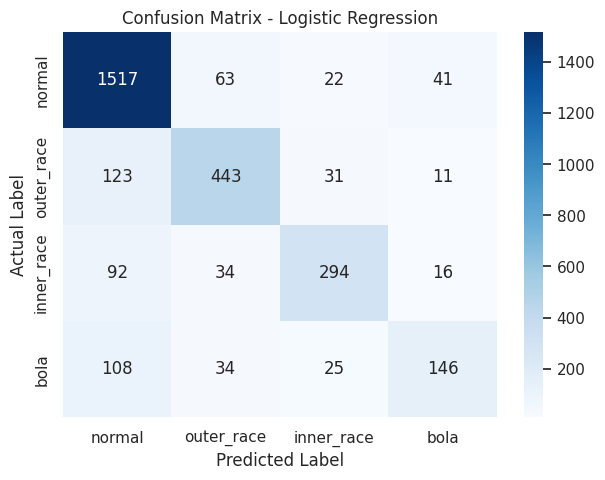

In [101]:
cm = confusion_matrix(
    y_val,
    y_val_pred,
    labels=["normal", "outer_race", "inner_race", "bola"]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["normal", "outer_race", "inner_race", "bola"],
    yticklabels=["normal", "outer_race", "inner_race", "bola"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

## Model Comparison

In [102]:

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "SVM": SVC(
        class_weight="balanced",
        random_state=42
    )
}

print("Model berhasil didefinisikan.")


Model berhasil didefinisikan.


In [103]:
# ==========================================
# TRAINING SELURUH MODEL
# ==========================================

trained_models = {}

for name, model in models.items():

    print(f"Training {name}...")

    model.fit(X_train_processed, y_train)

    trained_models[name] = model

print("\nSeluruh model berhasil dilatih.")


Training Logistic Regression...
Training Decision Tree...
Training Random Forest...
Training SVM...

Seluruh model berhasil dilatih.


In [104]:

# ==========================================
# EVALUASI MODEL COMPARISON
# ==========================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

results = []

for name, model in trained_models.items():

    # Prediksi validation set
    y_pred = model.predict(X_val_processed)

    # Menghitung metrik evaluasi
    accuracy = accuracy_score(y_val, y_pred)

    precision = precision_score(
        y_val, y_pred,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_val, y_pred,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_val, y_pred,
        average="macro",
        zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "Macro F1": f1
    })

# Membuat tabel hasil evaluasi
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

display(results_df.round(4))


,Model,Accuracy,Precision,Recall,Macro F1
0,Random Forest,0.8070,0.8212,0.6851,0.7312
1,SVM,0.7707,0.7144,0.7418,0.7218
2,Logistic Regression,0.7257,0.6597,0.7106,0.6754
3,Decision Tree,0.6957,0.6206,0.6325,0.6262


In [105]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Memastikan model terbaik ditentukan terlebih dahulu
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

# Prediksi menggunakan testing set
y_test_pred = best_model.predict(X_test_processed)

# Evaluasi
print("=== FINAL MODEL EVALUATION ===")
print("Model:", best_model_name)
print("Accuracy:", accuracy_score(y_test, y_test_pred))
print("Precision:", precision_score(y_test, y_test_pred, average="macro", zero_division=0))
print("Recall:", recall_score(y_test, y_test_pred, average="macro", zero_division=0))
print("Macro F1:", f1_score(y_test, y_test_pred, average="macro", zero_division=0))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred, zero_division=0))

=== FINAL MODEL EVALUATION ===
Model: Random Forest
Accuracy: 0.8203333333333334
Precision: 0.8365447031757975
Recall: 0.7106713841953449
Macro F1: 0.7547919427248099

Classification Report:
              precision    recall  f1-score   support

        bola       0.78      0.42      0.54       313
  inner_race       0.90      0.74      0.81       435
      normal       0.80      0.95      0.87      1644
  outer_race       0.88      0.74      0.80       608

    accuracy                           0.82      3000
   macro avg       0.84      0.71      0.75      3000
weighted avg       0.82      0.82      0.81      3000



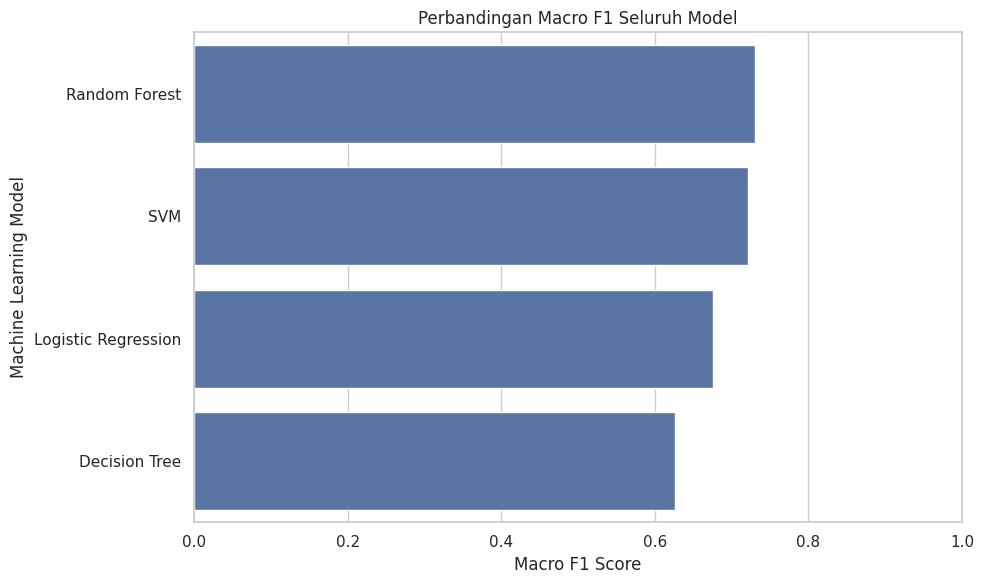

In [106]:

# ==========================================
# VISUALISASI PERBANDINGAN MODEL
# ==========================================

plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_df,
    x="Macro F1",
    y="Model"
)

plt.title("Perbandingan Macro F1 Seluruh Model")
plt.xlabel("Macro F1 Score")
plt.ylabel("Machine Learning Model")
plt.xlim(0, 1)

plt.tight_layout()
plt.show()


In [107]:

# ==========================================
# MENENTUKAN MODEL TERBAIK
# ==========================================

best_model_name = results_df.iloc[0]["Model"]

best_model = trained_models[best_model_name]

print("Model terbaik:", best_model_name)
print("Macro F1 Score:",
      results_df.iloc[0]["Macro F1"])


Model terbaik: Random Forest
Macro F1 Score: 0.7311522367431749


## Confusion Matrix - Best Model

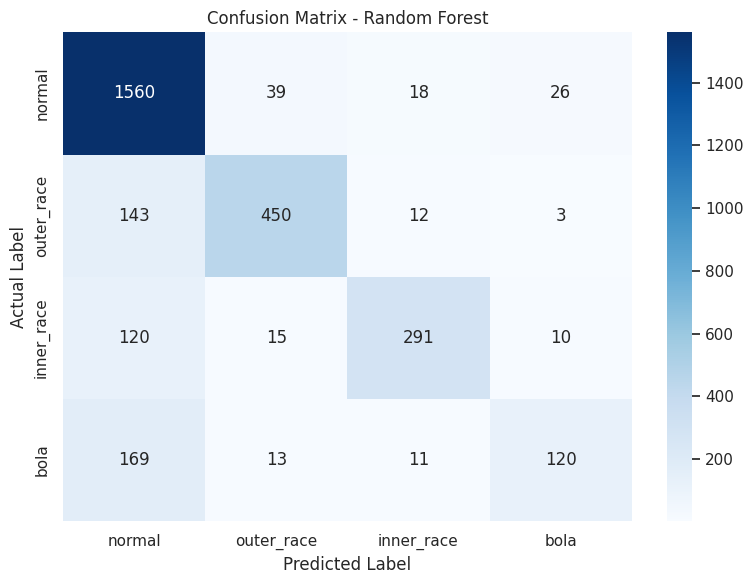

Classification Report:
              precision    recall  f1-score   support

      normal       0.78      0.95      0.86      1643
  outer_race       0.87      0.74      0.80       608
  inner_race       0.88      0.67      0.76       436
        bola       0.75      0.38      0.51       313

    accuracy                           0.81      3000
   macro avg       0.82      0.69      0.73      3000
weighted avg       0.81      0.81      0.80      3000



In [108]:

from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

# Prediksi menggunakan model terbaik pada validation set
y_val_best_pred = best_model.predict(X_val_processed)

# Urutan kelas
class_names = ["normal", "outer_race", "inner_race", "bola"]

# Confusion Matrix
cm = confusion_matrix(
    y_val,
    y_val_best_pred,
    labels=class_names
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title(f"Confusion Matrix - {best_model_name}")
plt.tight_layout()
plt.show()

# Classification Report
print("Classification Report:")
print(classification_report(
    y_val,
    y_val_best_pred,
    labels=class_names,
    zero_division=0
))


## Feature Importance

,Feature,Importance
7,num__energi_bpfo,0.170589
10,num__frekuensi_dominan_hz,0.158870
8,num__energi_bpfi,0.117810
9,num__energi_bsf,0.098573
5,num__kurtosis,0.090210
0,num__kecepatan_rpm,0.070352
2,num__suhu_housing_C,0.067929
3,num__rms_g,0.056756
6,num__crest_factor,0.053548
4,num__puncak_g,0.050615


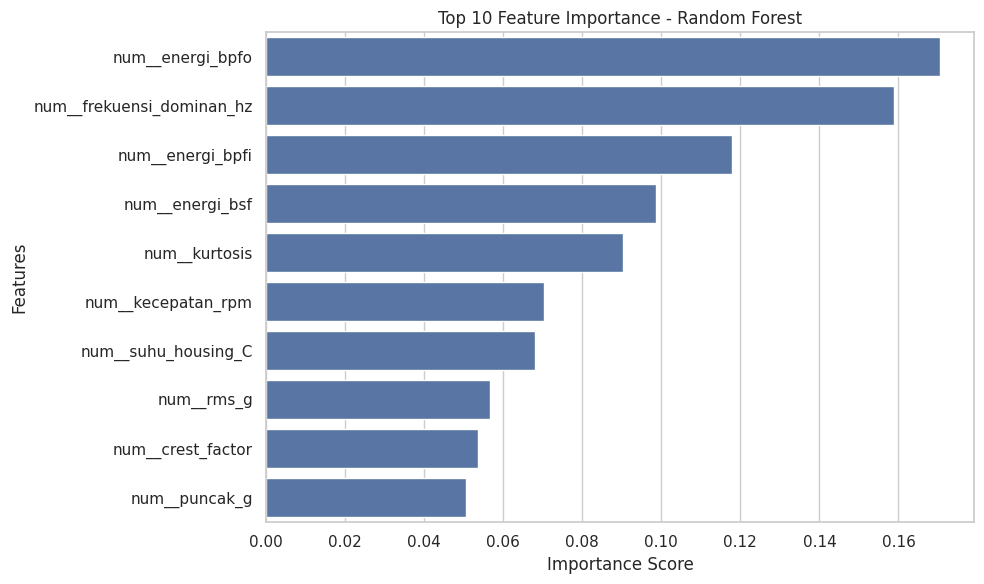

In [109]:

# ==========================================
# FEATURE IMPORTANCE ANALYSIS
# ==========================================

# Pastikan model terbaik mendukung feature_importances_
if hasattr(best_model, "feature_importances_"):

    importance = best_model.feature_importances_

    feature_importance = pd.DataFrame({
        "Feature": feature_names,
        "Importance": importance
    })

    feature_importance = feature_importance.sort_values(
        by="Importance",
        ascending=False
    )

    display(feature_importance)

    # Visualisasi 10 fitur terpenting
    plt.figure(figsize=(10, 6))

    sns.barplot(
        data=feature_importance.head(10),
        x="Importance",
        y="Feature"
    )

    plt.title(f"Top 10 Feature Importance - {best_model_name}")
    plt.xlabel("Importance Score")
    plt.ylabel("Features")
    plt.tight_layout()
    plt.show()

else:
    print(
        f"{best_model_name} tidak memiliki atribut "
        "feature_importances_."
    )


##Model Evaluation

In [110]:
results_df = results_df.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,Macro F1
0,Random Forest,0.8070,0.8212,0.6851,0.7312
1,SVM,0.7707,0.7144,0.7418,0.7218
2,Logistic Regression,0.7257,0.6597,0.7106,0.6754
3,Decision Tree,0.6957,0.6206,0.6325,0.6262


In [111]:
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

print("Model terbaik:", best_model_name)
print("Macro F1 Score:", results_df.iloc[0]["Macro F1"])

Model terbaik: Random Forest
Macro F1 Score: 0.7311522367431749


In [112]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Prediksi menggunakan testing set
y_test_pred = best_model.predict(X_test_processed)

# Evaluasi model
print("=== FINAL MODEL EVALUATION ===")
print("Model:", best_model_name)

print("Accuracy:", accuracy_score(y_test, y_test_pred))

print("Precision:", precision_score(
    y_test, y_test_pred,
    average="macro",
    zero_division=0
))

print("Recall:", recall_score(
    y_test, y_test_pred,
    average="macro",
    zero_division=0
))

print("Macro F1:", f1_score(
    y_test, y_test_pred,
    average="macro",
    zero_division=0
))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred,
    zero_division=0
))

=== FINAL MODEL EVALUATION ===
Model: Random Forest
Accuracy: 0.8203333333333334
Precision: 0.8365447031757975
Recall: 0.7106713841953449
Macro F1: 0.7547919427248099

Classification Report:
              precision    recall  f1-score   support

        bola       0.78      0.42      0.54       313
  inner_race       0.90      0.74      0.81       435
      normal       0.80      0.95      0.87      1644
  outer_race       0.88      0.74      0.80       608

    accuracy                           0.82      3000
   macro avg       0.84      0.71      0.75      3000
weighted avg       0.82      0.82      0.81      3000



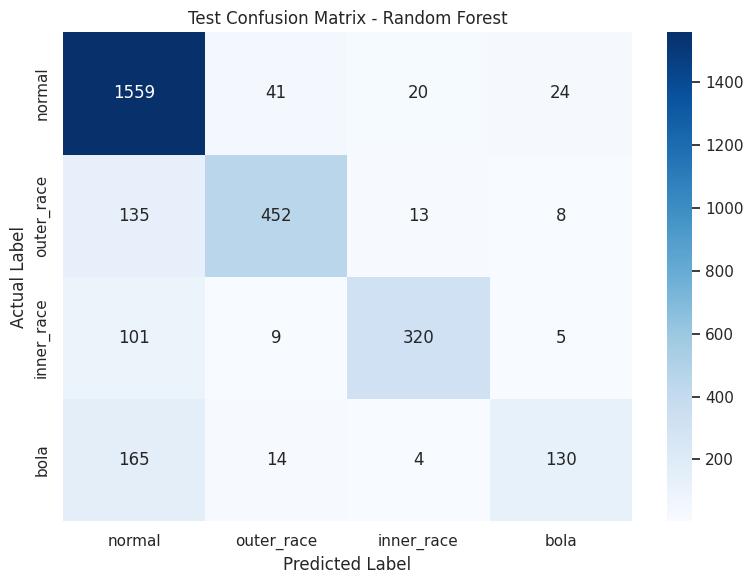

Classification Report - Test Set:
              precision    recall  f1-score   support

      normal       0.80      0.95      0.87      1644
  outer_race       0.88      0.74      0.80       608
  inner_race       0.90      0.74      0.81       435
        bola       0.78      0.42      0.54       313

    accuracy                           0.82      3000
   macro avg       0.84      0.71      0.75      3000
weighted avg       0.82      0.82      0.81      3000



In [113]:

from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

# Urutan kelas
class_names = ["normal", "outer_race", "inner_race", "bola"]

# Membuat confusion matrix dari test set
cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=class_names
)

# Visualisasi
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title(f"Test Confusion Matrix - {best_model_name}")
plt.tight_layout()
plt.show()

# Classification Report
print("Classification Report - Test Set:")
print(classification_report(
    y_test,
    y_test_pred,
    labels=class_names,
    zero_division=0
))


In [114]:

# Menghitung hasil evaluasi test set
test_results = {
    "Model": best_model_name,
    "Accuracy": accuracy_score(y_test, y_test_pred),
    "Precision": precision_score(
        y_test, y_test_pred,
        average="macro",
        zero_division=0
    ),
    "Recall": recall_score(
        y_test, y_test_pred,
        average="macro",
        zero_division=0
    ),
    "Macro F1": f1_score(
        y_test, y_test_pred,
        average="macro",
        zero_division=0
    )
}

# Membandingkan validation dan test
comparison_final = pd.DataFrame([
    {
        "Dataset": "Validation",
        "Accuracy": results_df.iloc[0]["Accuracy"],
        "Precision": results_df.iloc[0]["Precision"],
        "Recall": results_df.iloc[0]["Recall"],
        "Macro F1": results_df.iloc[0]["Macro F1"]
    },
    {
        "Dataset": "Test",
        "Accuracy": test_results["Accuracy"],
        "Precision": test_results["Precision"],
        "Recall": test_results["Recall"],
        "Macro F1": test_results["Macro F1"]
    }
])

display(comparison_final.round(4))


,Dataset,Accuracy,Precision,Recall,Macro F1
0,Validation,0.8070,0.8212,0.6851,0.7312
1,Test,0.8203,0.8365,0.7107,0.7548


## Model Saving

In [115]:
import os
import json
import zipfile
import joblib
import pandas as pd
from datetime import datetime

# ==========================================
# 1. MENYIAPKAN FOLDER ARTIFACT
# ==========================================

os.makedirs("artifacts", exist_ok=True)

# ==========================================
# 2. MENYIMPAN MODEL
# ==========================================

# Model terbaik dari Model Comparison
final_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", best_model)
])

model_path = "artifacts/bearing_diagnosis_model.joblib"

joblib.dump(final_pipeline, model_path)

print("Model berhasil disimpan!")

# ==========================================
# 3. MENYIMPAN METADATA
# ==========================================

metadata = {
    "project": "Bearing Fault Diagnosis",
    "model_name": best_model_name,
    "algorithm": type(best_model).__name__,
    "target": "kondisi",
    "classes": [
        str(c) for c in best_model.classes_
    ],
    "evaluation": {
        "validation_accuracy": float(
            results_df.iloc[0]["Accuracy"]
        ),
        "validation_macro_f1": float(
            results_df.iloc[0]["Macro F1"]
        )
    },
    "saved_at": datetime.now().isoformat()
}

metadata_path = "artifacts/metadata.json"

with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=4)

print("Metadata berhasil disimpan!")

# ==========================================
# 4. MENYIMPAN FEATURE IMPORTANCE
# ==========================================

if "feature_importance" in globals():

    feature_importance.to_csv(
        "artifacts/feature_importance.csv",
        index=False
    )

    print("Feature importance berhasil disimpan!")

# ==========================================
# 5. MEMBUAT FILE ZIP
# ==========================================

zip_path = "bearing_diagnosis_artifacts.zip"

files_to_zip = [
    "artifacts/bearing_diagnosis_model.joblib",
    "artifacts/metadata.json"
]

if os.path.exists("artifacts/feature_importance.csv"):
    files_to_zip.append(
        "artifacts/feature_importance.csv"
    )

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:

    for path in files_to_zip:
        z.write(path, arcname=os.path.basename(path))

print("\nZIP berhasil dibuat!")
print(
    "Ukuran ZIP:",
    round(os.path.getsize(zip_path) / 1024, 2),
    "KB"
)

# ==========================================
# 6. DOWNLOAD FILE (GOOGLE COLAB)
# ==========================================

try:
    from google.colab import files
    files.download(zip_path)

except ImportError:
    print(
        "Bukan di Google Colab. "
        "Silakan ambil file ZIP dari folder kerja."
    )


Model berhasil disimpan!
Metadata berhasil disimpan!
Feature importance berhasil disimpan!

ZIP berhasil dibuat!
Ukuran ZIP: 14762.15 KB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>